In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import roc_auc_score, log_loss
from scipy.stats import randint
from sklearn.isotonic import IsotonicRegression
df = pd.read_parquet("../data/train_features.parquet")

features = [c for c in df.columns if c not in ["case_id", "WEEK_NUM", "target"]]
print(df.shape, len(features))

(1000000, 95) 92


In [2]:
"""
some notes before i start RF modeling

.train model on both thin-file and rich data applicants together
.some features are equally divided(no differentiation to be extracted)
        4 cols like this (model won't learn much if you include them in training set)

.riskassesment_940T is STRONGEST PREDICTOR in data but not available for thin file app
.include 9th family


Goal #1 of this challenge = build set of models to predict probability of default
    why? credit card comps look at bureau info to see prob that company will repay loan
    need to accomodate thin file apps
    find balance and minimize risk of excluding these apps while increasing profit for company

    amex uses bureau info + models to get score ranges to determine risk factor invovled iwth that applicant 

Goal #2 of this challenge = how can we look at limited info to make decision instead of outright rejecting?
    should person be included or not, net gain, need EXPLAINABLE MODEL
    use output of first part(prob that person will be on default loan or not) and use as input for 2nd part to see if we should include applicants that model rejected


"""

"""
some important metrics to make sure we have is overall AUC, 
established AUC, thin-file AUC,
 and overall logloss. 
 That way we can compare models with the same metrics

  It can be used to evaluate customers with high credit risk,
    to detect fraud, and option pricing problems.

    RF combines multiple decision trees, each trained on random subset of data and features to reduce overfitting and improve prediction accuracy

    loss fxn in RF are determined by criterion parameter

    How is final prediction determined in RF?
        voting and averaging methods used to combine predictions made by individual decision trees

    Voting(classification) = determines final prediction
        each DT has its own class prediction and class with majority votes is selected as final predicted class
         helps improve overall classification accuracy and makes model elss prone to incorrect predictions due to individual tree variations or noise in data

    Averaging(Regression) = each DT has its own numerical predition and final prediction is average of all of these
        helps smooth out predictions and reduce variance of model ---> stable and accurate regression predictions


    For this RF model, we are using classification to see whether applicant will default on loan or not

    
    DT = classifier to seperate outcomes
        starts will all samples and searches for best feature and splitting value
        looks for best feature to make decision AND which cutoff the best split occures (threshold) = flexible

"""

'\nsome important metrics to make sure we have is overall AUC, \nestablished AUC, thin-file AUC,\n and overall logloss. \n That way we can compare models with the same metrics\n\n  It can be used to evaluate customers with high credit risk,\n    to detect fraud, and option pricing problems.\n\n    RF combines multiple decision trees, each trained on random subset of data and features to reduce overfitting and improve prediction accuracy\n\n    loss fxn in RF are determined by criterion parameter\n\n    How is final prediction determined in RF?\n        voting and averaging methods used to combine predictions made by individual decision trees\n\n    Voting(classification) = determines final prediction\n        each DT has its own class prediction and class with majority votes is selected as final predicted class\n         helps improve overall classification accuracy and makes model elss prone to incorrect predictions due to individual tree variations or noise in data\n\n    Averaging(R

In [5]:
#for splitting df into train and test split, do not split arbitrarily, use week_num as dividing num(0-91)
split = int(df["WEEK_NUM"].quantile(0.8))
print(split) #the cutoff week btwn training and testing is week 73

train_df = df[df["WEEK_NUM"] <= split]
val_df = df[df["WEEK_NUM"] > split] # testing model

#features = list(_catalog_features)
# features to not include in training set

#y_train is what model learns from and y_test is what you compare predictions against to get AUC

X_train, y_train = train_df[features], train_df["target"]
X_val, y_val = val_df[features], val_df["target"]
"""
ok so my plan is create hte train test split(using week_num as dividing num(0-91)), the use the RF model function and get accuracy scores. I also need to train the tree using different hyperparameter values whihc ill use a function to do so. https://medium.com/@denizgunay/random-forest-af5bde5d7e1e this website i was reading has some sample RF code but they put a lot more emphasiz on creating thresholds (probably for the splits) and finding the best features (which is pretty important for my task, as we want to see  
y = what we're predicting

"""#dict params will be unpacked in fxn with **
def train_eval_RF(X_train, y_train, X_val, y_val, **params):
    model = RandomForestClassifier(
        **params,
        n_jobs = -1, #using all CPU cores(faster speed for a large dataset)
        random_state=123
    )

    model.fit(X_train, y_train)

    #predictions on test set
    probabilities = model.predict_proba(X_val)[:,1] #default prob

    return roc_auc_score(y_val, probabilities), log_loss(y_val, probabilities)


#using randomized search now
param_distribution = {
    "max_depth": randint(6,20),
    "min_samples_leaf": randint(20,500),
    "max_features": ["sqrt", 0.3,0.5], #trying between feature value as floats and default which is squareroot
    "n_estimators": [50],
    "max_samples": [0.3],
}

#param function (finding optimal parameters)
results = []
for params in ParameterSampler(param_distribution, n_iter=10, random_state=123):
    auc_score, loss =  train_eval_RF(X_train, y_train, X_val, y_val, **params)
    results.append({**params, "auc_value": auc_score, "logloss_value": loss})
    print(params, "ROC_AUC: ", auc_score)

results_df = pd.DataFrame(results).sort_values("auc_value", ascending=False)
best_params = {k: results_df.iloc[0][k] for k in param_distribution}
print("Best params:", best_params)



73
{'max_depth': 19, 'max_features': 0.5, 'max_samples': 0.3, 'min_samples_leaf': 342, 'n_estimators': 50} ROC_AUC:  0.7684812634296172
{'max_depth': 18, 'max_features': 0.5, 'max_samples': 0.3, 'min_samples_leaf': 250, 'n_estimators': 50} ROC_AUC:  0.7684438082677052
{'max_depth': 7, 'max_features': 0.5, 'max_samples': 0.3, 'min_samples_leaf': 143, 'n_estimators': 50} ROC_AUC:  0.7682438532629229
{'max_depth': 15, 'max_features': 0.5, 'max_samples': 0.3, 'min_samples_leaf': 245, 'n_estimators': 50} ROC_AUC:  0.7684269091213485
{'max_depth': 6, 'max_features': 0.3, 'max_samples': 0.3, 'min_samples_leaf': 146, 'n_estimators': 50} ROC_AUC:  0.7650735532873213
{'max_depth': 15, 'max_features': 'sqrt', 'max_samples': 0.3, 'min_samples_leaf': 450, 'n_estimators': 50} ROC_AUC:  0.763780930556184
{'max_depth': 6, 'max_features': 0.3, 'max_samples': 0.3, 'min_samples_leaf': 359, 'n_estimators': 50} ROC_AUC:  0.7657781769391002
{'max_depth': 19, 'max_features': 'sqrt', 'max_samples': 0.3, 'min_

In [6]:
best_params = {
    "max_depth": 13,
    "min_samples_leaf": 360,
    "max_features": 0.5,
    "n_estimators": 100,
    "max_samples": 0.3
}

final_model = RandomForestClassifier(**best_params, n_jobs=-1, random_state=123)
final_model.fit(X_train, y_train)
val_probs = final_model.predict_proba(X_val)[:,1]
for name, mask in [("Established", val_df["thin_file"] == 0), ("Thin-file", val_df["thin_file"] == 1)]:
    y_seg = y_val[mask]
    p_seg = val_probs[mask.values]
    print(name, "| AUC:", round(roc_auc_score(y_seg, p_seg), 3),
          "| actual default:", round(y_seg.mean(), 3),
          "| avg predicted:", round(p_seg.mean(), 3))

Established | AUC: 0.795 | actual default: 0.164 | avg predicted: 0.164
Thin-file | AUC: 0.711 | actual default: 0.202 | avg predicted: 0.269


In [7]:
weeks = np.sort(train_df["WEEK_NUM"].unique())
blocks = np.array_split(weeks, 5)

folds = []
for k in range(1, 5):
    fold_train_weeks = np.concatenate(blocks[:k])
    fold_test_weeks = blocks[k]
    folds.append((fold_train_weeks, fold_test_weeks))

for i, (tr_w, te_w) in enumerate(folds, start=1):
    n_tr = train_df["WEEK_NUM"].isin(tr_w).sum()
    n_te = train_df["WEEK_NUM"].isin(te_w).sum()
    print("Fold", i, "| train weeks:", tr_w.min(), "-", tr_w.max(), "(", n_tr, "loans )",
          "| test weeks:", te_w.min(), "-", te_w.max(), "(", n_te, "loans )")

Fold 1 | train weeks: 0 - 14 ( 163171 loans ) | test weeks: 15 - 29 ( 162982 loans )
Fold 2 | train weeks: 0 - 29 ( 326153 loans ) | test weeks: 30 - 44 ( 163010 loans )
Fold 3 | train weeks: 0 - 44 ( 489163 loans ) | test weeks: 45 - 59 ( 162970 loans )
Fold 4 | train weeks: 0 - 59 ( 652133 loans ) | test weeks: 60 - 73 ( 152164 loans )


In [8]:
fold_rows = []
for i, (tr_w, te_w) in enumerate(folds, start=1):
    tr = train_df[train_df["WEEK_NUM"].isin(tr_w)]
    te = train_df[train_df["WEEK_NUM"].isin(te_w)]

  
    fold_model = RandomForestClassifier(**best_params, n_jobs=-1, random_state=123)
    fold_model.fit(tr[features], tr["target"])
    fold_probs = fold_model.predict_proba(te[features])[:,1]

    y_te = te["target"].values
    est = (te["thin_file"] == 0).values
    fold_rows.append({"fold": i,
                      "trees": fold_model.n_estimators,
                      "overall_AUC": round(roc_auc_score(y_te, fold_probs), 4),
                      "established_AUC": round(roc_auc_score(y_te[est], fold_probs[est]), 4),
                      "thin_AUC": round(roc_auc_score(y_te[~est], fold_probs[~est]), 4)})

fold_results = pd.DataFrame(fold_rows)
print(fold_results)
print("Average overall AUC:", round(fold_results["overall_AUC"].mean(), 4),
      "| spread (std):", round(fold_results["overall_AUC"].std(), 4))

   fold  trees  overall_AUC  established_AUC  thin_AUC
0     1    100       0.7810           0.7939    0.7111
1     2    100       0.7805           0.7972    0.7185
2     3    100       0.7758           0.7965    0.7155
3     4    100       0.7710           0.7945    0.7138
Average overall AUC: 0.7771 | spread (std): 0.0047


In [9]:
y = y_val.values
repaid = (y == 0)
thin = (val_df["thin_file"] == 1).values

mid_week = val_df["WEEK_NUM"].median()
early = (val_df["WEEK_NUM"] <= mid_week).values
late = ~early

# step 1: how far off is the model on thin-file loans in the early half?
factor = y[thin & early].mean() / val_probs[thin & early].mean()
print("correction factor:", round(factor, 3))

# step 2: multiply the thin-file predictions by that factor
val_probs_fixed = val_probs.copy()
val_probs_fixed[thin] = val_probs[thin] * factor

# step 3: check it on the late half
check = thin & late
print("Thin-file avg predicted before:", round(val_probs[check].mean(), 3),
      "| after:", round(val_probs_fixed[check].mean(), 3),
      "| actual:", round(y[check].mean(), 3))

correction factor: 0.767
Thin-file avg predicted before: 0.269 | after: 0.206 | actual: 0.196


In [10]:
'''
laplacian correction negatively effects RF accuracy, AUC
trying isotonic regression


'''
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

iso_r = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip').fit(val_probs[thin & early], y[thin & early])
val_probs_iso = val_probs.copy()
val_probs_iso[thin] = iso_r.predict(val_probs[thin])

def calibrate(y_true, p, n_bins=10):
    bins = np.clip((p*n_bins).astype(int),0,n_bins-1)
    total=0
    for b in range(n_bins):
        in_bin = bins == b
        if in_bin.any():
            total +=in_bin.mean() * abs(y_true[in_bin].mean() - p[in_bin].mean())
    return total


#print out report (check = thin and late)
iso_effective = val_probs_iso[thin & early].mean() / val_probs[thin & early].mean()
print("isotonic effective factor (average scaling):", round(iso_effective, 3))

print("Thin-file avg predicted before:", round(val_probs[check].mean(), 3),
      "| after:", round(val_probs_iso[check].mean(), 3),
      "| actual:", round(y[check].mean(), 3))



isotonic effective factor (average scaling): 0.767
Thin-file avg predicted before: 0.269 | after: 0.207 | actual: 0.196


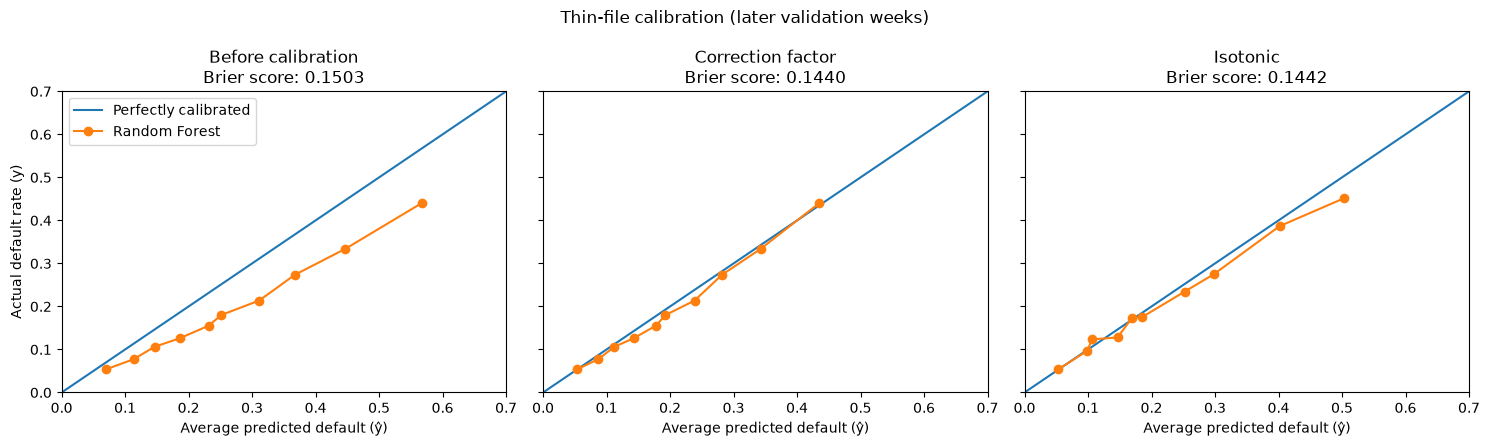

In [11]:
#printing out calibration plot
from sklearn.calibration import calibration_curve

versions = [("Before calibration", val_probs),
            ("Correction factor", val_probs_fixed),
            ("Isotonic", val_probs_iso)]

fig, axes = plt.subplots(1, len(versions), figsize=(15, 4.5), sharey=True)
for ax, (name, p) in zip(axes, versions):
    actual, predicted = calibration_curve(y[check], p[check], n_bins=10, strategy="quantile")
    ax.plot([0, 1], [0, 1], label="Perfectly calibrated")
    ax.plot(predicted, actual, marker="o", label="Random Forest")
    ax.set_title(f"{name}\nBrier score: {brier_score_loss(y[check], p[check]):.4f}")
    ax.set_xlabel("Average predicted default (ŷ)")
    ax.set_xlim(0, 0.7)
    ax.set_ylim(0, 0.7)
axes[0].set_ylabel("Actual default rate (y)")
axes[0].legend()
plt.suptitle("Thin-file calibration (later validation weeks)")
plt.tight_layout()
plt.show()


In [12]:
def summarize(p, cutoff=0.20):
    approve = p < cutoff
    repaid = y == 0
    profit = 2000 * (approve & repaid & late).sum() - 8000 * (approve & ~repaid & late).sum()
    est_rate = approve[late & repaid & ~thin].mean()
    thin_rate = approve[late & repaid & thin].mean()
    return {
        "Overall AUC":                      round(roc_auc_score(y[late], p[late]), 4),
        "Thin-file predicted default (%)":  round(100 * p[late & thin].mean(), 1),
        "Thin-file actual default (%)":     round(100 * y[late & thin].mean(), 1),
        "Profit ($)":                       int(profit),
        "Repayers approved, established (%)": round(100 * est_rate, 1),
        "Repayers approved, thin-file (%)":   round(100 * thin_rate, 1),
        "Inclusion gap (points)":           round(100 * (est_rate - thin_rate), 1),
    }

pd.set_option("display.float_format", "{:,.3f}".format)
summary = pd.DataFrame({"Before": summarize(val_probs), "After": summarize(val_probs_fixed)})
summary["Change"] = summary["After"] - summary["Before"]
summary


,Before,After,Change
Overall AUC,0.767,0.771,0.004
Thin-file predicted default (%),26.900,20.600,-6.300
Thin-file actual default (%),19.600,19.600,0.000
Profit ($),"63,242,000.000","65,522,000.000","2,280,000.000"
"Repayers approved, established (%)",77.500,77.500,0.000
"Repayers approved, thin-file (%)",41.300,64.900,23.600
Inclusion gap (points),36.200,12.600,-23.600
